# 04 &nbsp;How many customers do we need?

**The question.** The plan in notebook 02 says an email is worth sending if it lifts revenue by at least **11 cents per customer**. How big does a test have to be to reliably catch a lift that size? And was *this* test big enough?

**The approach.** The textbook formula answers in one line, but it assumes revenue behaves like a smooth bell curve. Notebook 03 showed it doesn't. So the formula's answer is checked against simulation: resample real no-email customers, add a known lift, and count how often the test catches it.

**How the lift is added matters.** Notebook 01 found the emails worked by turning more people into buyers, not by making baskets bigger. So the simulation adds the lift the same way: it turns some non-buyers into buyers who spend like real buyers. Simulating the effect the way it actually happens is the point.

In [1]:
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.data import load_hillstrom
from exptoolkit.power import (mde_means, n_for_power, power_means, power_proportions,
                              required_n_means, required_n_proportions, simulate_power)
from exptoolkit.spec import load_spec

style.use_style()
spec = load_spec("hillstrom_email.yaml")
alpha, target = spec.statistics["alpha"], spec.statistics["power"]
lift = spec.economics.worthwhile_lift

df = load_hillstrom()
control = df[df["arm"] == "control"]
actual_n = int(df["arm"].value_counts().min())

sd = control["spend"].std()
buy_rate = control["conversion"].mean()
basket = control.loc[control["spend"] > 0, "spend"].mean()
lift_in_purchases = lift / basket

print(f"Lift worth acting on:   ${lift:.3f} revenue per customer")
print(f"Same lift as purchases: +{100 * lift_in_purchases:.2f} points on a {buy_rate:.2%} buying rate "
      f"(average basket ${basket:.0f})")

Lift worth acting on:   $0.114 revenue per customer
Same lift as purchases: +0.10 points on a 0.57% buying rate (average basket $114)


## 1. What the textbook formula says

In [2]:
formula = pd.DataFrame({
    "Customers per group needed": [
        required_n_means(sd, lift, alpha, target),
        required_n_proportions(buy_rate, lift_in_purchases, alpha, target),
    ],
}, index=["Measured on revenue", "Measured on purchases"])
formula.style.format("{:,.0f}")

,Customers per group needed
Measured on revenue,"161,394"
Measured on purchases,"96,662"


## 2. What simulation on real customers says

1,000 simulated tests at each of 12 sizes, for both ways of measuring the same lift. This takes about a minute.

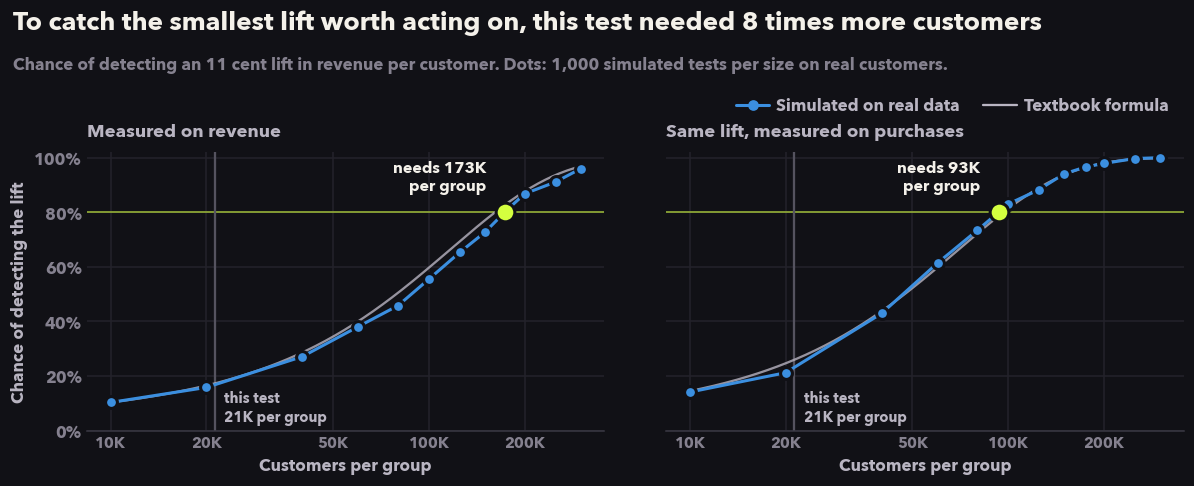

In [3]:
sizes = [10_000, 20_000, 40_000, 60_000, 80_000, 100_000, 125_000, 150_000,
         175_000, 200_000, 250_000, 300_000]
panels = {}
for metric, title, curve in [
    ("spend", "Measured on revenue", lambda n: power_means(sd, lift, n, alpha)),
    ("conversion", "Same lift, measured on purchases",
     lambda n: power_proportions(buy_rate, lift_in_purchases, n, alpha)),
]:
    simulated = [simulate_power(control["spend"], lift, n, metric=metric, n_sims=1000,
                                alpha=alpha, seed=n) for n in sizes]
    panels[title] = {"sizes": sizes, "simulated": simulated, "formula": curve,
                     "n_needed": n_for_power(sizes, simulated, target)}

fig, axes = plots.power_curves_plot(panels, actual_n=actual_n, target=target)
style.headline(
    fig,
    "To catch the smallest lift worth acting on, this test needed 8 times more customers",
    "Chance of detecting an 11 cent lift in revenue per customer. "
    "Dots: 1,000 simulated tests per size on real customers.",
)
style.save(fig, "power")

In [4]:
summary = pd.DataFrame({
    "Formula": formula["Customers per group needed"].values,
    "Simulation": [panels[t]["n_needed"] for t in panels],
}, index=formula.index)
summary["Buyers per group (simulation)"] = summary["Simulation"] * buy_rate
summary["Times this test"] = summary["Simulation"] / actual_n
summary.style.format({"Formula": "{:,.0f}", "Simulation": "{:,.0f}",
                      "Buyers per group (simulation)": "{:,.0f}", "Times this test": "{:.1f}x"})

,Formula,Simulation,Buyers per group (simulation),Times this test
Measured on revenue,"161,394","172,963",990,8.1x
Measured on purchases,"96,662","93,264",534,4.4x


In [5]:
this_test = simulate_power(control["spend"], lift, actual_n, n_sims=2000, alpha=alpha, seed=1)
print(f"This test: {actual_n:,} customers per group")
print(f"Chance it would catch an 11 cent lift: {this_test:.0%}")
print(f"Smallest lift it could reliably catch:  ${mde_means(sd, actual_n, alpha, target):.2f} per customer")

This test: 21,306 customers per group
Chance it would catch an 11 cent lift: 16%
Smallest lift it could reliably catch:  $0.31 per customer


## 3. What this tells us

**This test was too small for the question the business is asking.** To reliably catch the smallest lift worth acting on, it needed about **173,000 customers per group**, 8 times what it had. At its real size it had roughly a **1 in 6** chance of catching an 11 cent lift. It could only reliably catch lifts of about **31 cents** or more.

That changes how a result should be read:

- **A significant result is still informative.** Notebook 01 suggests both emails lifted revenue by more than 31 cents per customer, so this test was big enough to see them. The formal readout comes in notebook 06.
- **A "no significant difference" would have meant almost nothing.** If an email had a real, worthwhile lift of 11 cents, this test would have missed it 5 times out of 6. Calling that email "not worth sending" would have been wrong.

**The formula is close, but optimistic on revenue.** It says 161,000 per group; the simulation says 173,000. Adding buyers also adds variance, which the formula doesn't account for. On purchases, formula and simulation agree.

**Measuring the mechanism is cheaper than measuring the money.** The same economic lift, measured as purchases instead of revenue, needs about **93,000** customers per group, roughly half. Purchases ignore how much each basket happens to cost, which is mostly noise here.

## What I'd change in the next test

1. **Size it for the decision, not for a guess.** Use the smallest lift worth acting on from the plan, and size by simulation on recent data.
2. **Consider purchases as the primary metric**, with revenue per buyer as a guardrail. That has to be decided *before* the next test, not swapped in after this one. The plan in notebook 02 stays as written.
3. **Reduce noise instead of only adding customers.** Customers' past spend predicts their future spend. Notebook 06 uses it (CUPED) to shrink the noise in revenue, which works like a bigger test for free.